In [2]:
import numpy as np
from pycvxset import Polytope
import os
import sys
from pathlib import Path

REPO_ROOT= Path('G:/OneDrive - Politecnico di Torino/Research Material/(q)LPV MPC  - Koopman Operator MPC/Code/RAMPC')

try:
    from rampc import CRAMPC
except ModuleNotFoundError:
    if str(REPO_ROOT) not in sys.path:
        sys.path.insert(0, str(REPO_ROOT))
    from src import CRAMPC
    from src.tools.invariance_tools import InvariantSet, GainSynthesis
    from src.tools.adaptive_tools import SetUpdater

In [ ]:
C = np.block([[[np.eye(3)]], [[np.zeros((3,3))]], [[np.zeros((3,3))]], [[np.zeros((3,3))]]]).transpose(1, 2, 0)
C.shape


In [ ]:
os.path.curdir
npzfile = np.load('.\system_matrices.npz')
A, B = npzfile['arr_0'], npzfile['arr_1']
# np.round(A,3), np.round(B,3)
max_p, min_p = npzfile['arr_2'][:,1], npzfile['arr_2'][:,0]

In [ ]:
A_B=np.concatenate( (A, B), axis=1).transpose(2, 0, 1)
C = np.stack([np.eye(3), np.zeros((3,3)), np.zeros((3,3)), np.zeros((3,3))], axis=2)
W = Polytope(
                A=np.block([[np.eye(3)], [-np.eye(3)]]), b=np.array([0.01, 0.001, 0.1*np.pi/180, 0.01, 0.001, 0.1*np.pi/180])
            )

E = Polytope(
                A=np.block([[np.eye(3)], [-np.eye(3)]]), b=np.array([0.01, 0.001, 0.1*np.pi/180, 0.01, 0.001, 0.1*np.pi/180])
            )

Theta_c = Polytope()

In [ ]:
Theta = Polytope(A=np.block([[np.eye(3)], [-np.eye(3)]]), b=np.block([np.array(max_p), -np.array(min_p)]))  # np.block([np.array(max_p), -np.array(min_p)])
Theta.plot()
Theta.V

SetUpdater(A_B, C.transpose(2, 0, 1), Theta, Theta_c, W, E, 1)

In [ ]:
theta_v = np.concatenate((np.ones((8,1)),Theta.V), 1) 

Av = np.einsum('ijk,lk->ijl', A, theta_v)
Bv = np.einsum('ijk,lk->ijl', B, theta_v)


The Polytope $\mathcal{Z} = \mathcal{X} \cross \mathcal{U}$ for the system with states $ x = \[ \Delta \theta, v_x, v_y, \omega\]^T$ and inputs $u = \[v_x, \omega\]$. Unsing unbounded quantities may lead to unexisting controller. However one can set the contribute of the stabilizing gain at zero.


In [ ]:
z = Polytope(A=np.block([[np.eye(5)], [-np.eye(5)]]), b=np.array([0.46, 0.1, 1.90, 0.46, 1.90, 0.46, 0.1, 1.90, 0.46, 1.90]))

Q = np.eye(3)
R = np.eye(2)
# R = np.diag([1/(0.46**2), 1/(1.90**2)])  # np.diag([1/(0.46**2), 1/(1.90**2), 1, 1])
gain_synth = GainSynthesis(
            A[:,:,0], B[:,:,0],
            Q=Q, R=R,
            Z_bnd=z, W=Polytope(),
            mode='LQR', contraction_factor=.999)
gain_synth.synthesize_controller()

In [ ]:
K = gain_synth.get_gain()
P = gain_synth.get_terminal_weight()
K, P


In [ ]:
invariance_ingredients = InvariantSet(z,A[:,:,0],B[:,:,0],K,1)
poly = invariance_ingredients.compute_invariant_set()


In [ ]:
z = Polytope(A=np.block([[np.eye(5)], [-np.eye(5)]]), b=np.array([0.46, 0.1, 1.90, 0.46, 1.90, 0.46, 0.1, 1.90, 0.46, 1.90]))

Q = np.eye(3)
R = np.eye(2)
# R = np.diag([1/(0.46**2), 1/(1.90**2)])  # np.diag([1/(0.46**2), 1/(1.90**2), 1, 1])
gain_synth = GainSynthesis(
            Av, Bv,
            Q=Q, R=R,
            Z_bnd=z, W=W,
            mode='LQR', contraction_factor=.999)
gain_synth.synthesize_controller()

K = gain_synth.get_gain()
P = gain_synth.get_terminal_weight()

np.savez('offline_matrices',K,P)

invariance_ingredients = InvariantSet(z,Av,Bv,K,.999)
poly = invariance_ingredients.compute_invariant_set()

In [ ]:
Theta.chebyshev_centering()

In [ ]:
A = np.block([[[np.eye(3)]],[[np.zeros((3,3))]],[[np.zeros((3,3))]]])
A = A.transpose(1,2,0).copy()

B = np.block([[[np.zeros((2,2))],[0, 1]],[[1, 0], [np.zeros((2,2))]],[[np.zeros((1,2))],[1, 0], [np.zeros((1,2))]]])/30
B = B.transpose(1,2,0).copy()


C = np.block([[[np.eye(3)]],[[np.zeros((3,3))]],[[np.zeros((3,3))]]])
C = C.transpose(1,2,0).copy()
A_B=np.concatenate( (A, B), axis=1).transpose(2, 0, 1)
A_B.shape

(3, 3, 5)

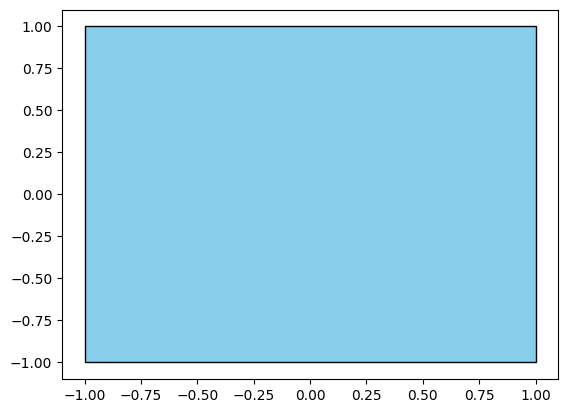

In [5]:
W = Polytope(
                A=np.block([[np.eye(3)], [-np.eye(3)]]), b=np.array([0.01, 0.01, 0.01*np.pi/180, 0.01, 0.01, 0.01*np.pi/180])
            )

E = Polytope(
                A=np.block([[np.eye(3)], [-np.eye(3)]]), b=np.array([0.01, 0.01, 0.01*np.pi/180, 0.01, 0.01, 0.01*np.pi/180])
            )

Theta_c = Polytope()

Theta = Polytope(A=np.block([[np.eye(2)], [-np.eye(2)]]), b=np.block([1,1,1,1]))  # np.block([np.array(max_p), -np.array(min_p)])
Theta.plot()
Theta.V

SetUpdater(A_B, C.transpose(2, 0, 1), Theta, Theta_c, W, E, 1)

theta_v = np.concatenate((np.ones((4,1)),Theta.V), 1) 

Av = np.einsum('ijk,lk->ijl', A, theta_v)
Bv = np.einsum('ijk,lk->ijl', B, theta_v)

In [15]:
z = Polytope(A=np.block([[np.eye(2), np.zeros((2,3))], [np.zeros((2,3)), np.eye(2)], [-np.eye(2), np.zeros((2,3))], [np.zeros((2,3)), -np.eye(2)]]),
             b=np.array([5, 2.5, 0.46, 1.90, 5, 2.5, 0.46, 1.90]))

Q = np.eye(3)
R = np.eye(2)
# R = np.diag([1/(0.46**2), 1/(1.90**2)])  # np.diag([1/(0.46**2), 1/(1.90**2), 1, 1])
gain_synth = GainSynthesis(
            Av, Bv,
            Q=Q, R=R,
            Z_bnd=z, W=Polytope(),
            mode='LQR', contraction_factor=.999)
gain_synth.synthesize_controller()

K = gain_synth.get_gain()
P = gain_synth.get_terminal_weight()

np.savez('kin_offline_mat',K,P)

invariance_ingredients = InvariantSet(z,Av,Bv,K,1)
poly = invariance_ingredients.compute_invariant_set()

Convergence reached after 1 iterations


In [ ]:
z = Polytope(A=np.block([[np.eye(2), np.zeros((2,3))], [np.zeros((2,3)), np.eye(2)], [-np.eye(2), np.zeros((2,3))], [np.zeros((2,3)), -np.eye(2)]]),
             b=np.array([5, 2.5, 0.46, 1.90, 5, 2.5, 0.46, 1.90]))
z.dim

## Incremental Model

In [ ]:
A = np.block([[[np.zeros((3,3))]],[[np.zeros((3,3))]],[[np.zeros((3,3))]]])
A = A.transpose(1,2,0).copy()

B = np.block([[[np.zeros((2,2))],[0, 1]],[[1, 0], [np.zeros((2,2))]],[[np.zeros((1,2))],[1, 0], [np.zeros((1,2))]]])/30
B = B.transpose(1,2,0).copy()


C = np.block([[[np.eye(3)]],[[np.zeros((3,3))]],[[np.zeros((3,3))]]])
C = C.transpose(1,2,0).copy()
A_B=np.concatenate( (A, B), axis=1).transpose(2, 0, 1)
A_B.shape

In [ ]:
W = Polytope(
                A=np.block([[np.eye(3)], [-np.eye(3)]]), b=np.array([0.01, 0.01, 0.01*np.pi/180, 0.01, 0.01, 0.01*np.pi/180])
            )

E = Polytope(
                A=np.block([[np.eye(3)], [-np.eye(3)]]), b=np.array([0.01, 0.01, 0.01*np.pi/180, 0.01, 0.01, 0.01*np.pi/180])
            )

Theta_c = Polytope()

Theta = Polytope(A=np.block([[np.eye(2)], [-np.eye(2)]]), b=np.block([1,1,1,1]))  # np.block([np.array(max_p), -np.array(min_p)])
Theta.plot()
Theta.V

SetUpdater(A_B, C.transpose(2, 0, 1), Theta, Theta_c, W, E, 1)

theta_v = np.concatenate((np.ones((4,1)),Theta.V), 1) 

Av = np.einsum('ijk,lk->ijl', A, theta_v)
Bv = np.einsum('ijk,lk->ijl', B, theta_v)

In [ ]:
z = Polytope(A=np.block([[np.eye(5)], [-np.eye(5)]]),
             b=np.array([5, 2.5, 0.46, 1.90, 5, 2.5, 0.46, 1.90]))

Q = np.eye(3)
R = np.eye(2)
# R = np.diag([1/(0.46**2), 1/(1.90**2)])  # np.diag([1/(0.46**2), 1/(1.90**2), 1, 1])
gain_synth = GainSynthesis(
            Av, Bv,
            Q=Q, R=R,
            Z_bnd=z, W=Polytope(),
            mode='LQR', contraction_factor=.999)
gain_synth.synthesize_controller()

K = gain_synth.get_gain()
P = gain_synth.get_terminal_weight()

np.savez('incremental_offline_mat',K,P)

invariance_ingredients = InvariantSet(z,Av,Bv,K,1)
poly = invariance_ingredients.compute_invariant_set()

In [ ]:
import numpy as np

circle_angle = np.arange(0.0,2*np.pi,2*np.pi/(30*20))

circle_pose = np.array([np.cos(circle_angle)-1, np.sin(circle_angle), circle_angle-np.pi/2]).T

list(circle_pose[0,:])

[np.float64(0.0),
 np.float64(0.0),
 np.float64(-1.5707963267948966),
 np.float64(-5.4830634487856855e-05),
 np.float64(0.010471784116245792),
 np.float64(-1.5603243512829306),
 np.float64(-0.0002193165251545004),
 np.float64(0.020942419883356957),
 np.float64(-1.5498523757709646),
 np.float64(-0.0004934396342684),
 np.float64(0.031410759078128285),
 np.float64(-1.5393804002589986),
 np.float64(-0.0008771699011416167),
 np.float64(0.04187565372919962),
 np.float64(-1.5289084247470326),
 np.float64(-0.0013704652454261668),
 np.float64(0.05233595624294383),
 np.float64(-1.5184364492350666),
 np.float64(-0.001973271571728441),
 np.float64(0.06279051952931336),
 np.float64(-1.5079644737231006),
 np.float64(-0.002685522775541904),
 np.float64(0.07323819712763167),
 np.float64(-1.4974924982111348),
 np.float64(-0.00350714075049563),
 np.float64(0.08367784333231548),
 np.float64(-1.4870205226991688),
 np.float64(-0.004438035396920004),
 np.float64(0.09410831331851431),
 np.float64(-1.47654854